# Health baseline: Dummy vs. Random Forest

Veritas AI Hackathon 2026, Health track. Compares a "most frequent class" baseline with a
Random Forest on real health data from Hugging Face.

**How to use:** pick a dataset in the next cell, then **Runtime → Run all**.

> Prototype for learning only. Not medical advice.

In [23]:
# Choose "heart" (UCI Heart Disease, 303 patients) or "diabetes" (Pima, 768 patients)
DATASET = "heart"

In [24]:
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, recall_score
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline

RANDOM_STATE = 42
HF = "https://huggingface.co/datasets"

DATASETS = {
    "heart": {
        "url": f"{HF}/skrishna/heart_disease_uci/resolve/main/test.csv",
        "target": "target",  # 1 = heart disease (>50% narrowing)
        "positive": "heart disease",
        "zero_means_missing": [],
        "group_col": "sex",  # 1 = male, 0 = female
        "group_names": {0: "female", 1: "male"},
    },
    "diabetes": {
        "url": f"{HF}/khoaguin/pima-indians-diabetes-database/resolve/main/diabetes.csv",
        "target": "y",  # 1 = diabetes
        "positive": "diabetes",
        # A glucose or BMI of 0 is impossible: these zeros are missing values.
        "zero_means_missing": ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"],
        "group_col": None,
        "group_names": {},
    },
}

## 1. Load the data

In [25]:
cfg = DATASETS[DATASET]
df = pd.read_csv(cfg["url"])
df = df.replace("?", np.nan)  # some UCI copies mark missing values with "?"
for col in cfg["zero_means_missing"]:
    df[col] = df[col].replace(0, np.nan)
y = df.pop(cfg["target"]).astype(int)
X = df.apply(pd.to_numeric, errors="coerce")

print(f"{DATASET}: {len(X)} patients, {X.shape[1]} features, "
      f"{y.mean():.0%} with {cfg['positive']}")
print(f"Missing values to fill in: {int(X.isna().sum().sum())}")
X.head()

heart: 303 patients, 13 features, 46% with heart disease
Missing values to fill in: 6


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0


## 2. Split into train and test sets

In [26]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print(f"Train: {len(X_train)} rows | Test: {len(X_test)} rows")

Train: 242 rows | Test: 61 rows


## 3. Train the baseline and the Random Forest

In [27]:
baseline = DummyClassifier(strategy="most_frequent")
model = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("forest", RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE)),
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for label, clf in [("Baseline (most frequent)", baseline), ("Random Forest", model)]:
    # Cross-validation on the training set only - the test set stays unseen.
    cv_scores = cross_val_score(clf, X_train, y_train, cv=cv, scoring="accuracy")
    clf.fit(X_train, y_train)
    preds = clf.predict(X_test)
    rows.append({
        "Model": label,
        "CV accuracy": f"{cv_scores.mean():.1%} ± {cv_scores.std():.1%}",
        "Test accuracy": f"{accuracy_score(y_test, preds):.1%}",
        "Test recall": f"{recall_score(y_test, preds, zero_division=0):.1%}",
    })

print(f"Recall = share of real {cfg['positive']} cases the model caught.")
pd.DataFrame(rows).set_index("Model")

Recall = share of real heart disease cases the model caught.


,CV accuracy,Test accuracy,Test recall
Model,,,
Baseline (most frequent),54.1% ± 0.6%,54.1%,0.0%
Random Forest,81.0% ± 1.7%,91.8%,96.4%


## 4. Fairness check: does it work equally well for each group?

In [28]:
if cfg["group_col"]:
    preds = model.predict(X_test)
    out = []
    for value, group in cfg["group_names"].items():
        mask = (X_test[cfg["group_col"]] == value).to_numpy()
        if mask.sum() == 0:
            continue
        out.append({
            "Group": group,
            "n": int(mask.sum()),
            "Accuracy": f"{accuracy_score(y_test[mask], preds[mask]):.1%}",
            "Recall": f"{recall_score(y_test[mask], preds[mask], zero_division=0):.1%}",
        })
    print("Small groups -> noisy numbers. Report them, but don't over-read them.")
    display(pd.DataFrame(out).set_index("Group"))
else:
    print("This dataset has no group column to compare.")

Small groups -> noisy numbers. Report them, but don't over-read them.


,n,Accuracy,Recall
Group,,,
female,20,100.0%,100.0%
male,41,87.8%,95.2%


## 5. Which features mattered most?

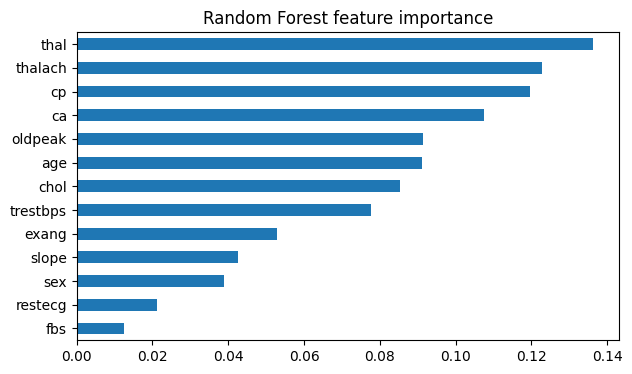

In [29]:
importances = pd.Series(
    model.named_steps["forest"].feature_importances_, index=X.columns
).sort_values()
importances.plot.barh(title="Random Forest feature importance", figsize=(7, 4));

## Sources

- UCI Heart Disease (Cleveland): https://huggingface.co/datasets/skrishna/heart_disease_uci
  (original: https://archive.ics.uci.edu/dataset/45/heart+disease)
- Pima Indians Diabetes Database: https://huggingface.co/datasets/khoaguin/pima-indians-diabetes-database
- AI tools used: Claude (coding assistant)